In [1]:
# Run from the workshop root (workshops/w2): src/, artifacts/ and export-* are resolved relative to it.
import os
from pathlib import Path
_here = Path.cwd().resolve()
W2_ROOT = next(p for p in (_here, *_here.parents) if p.name == "w2" and (p / "src").is_dir())
os.chdir(W2_ROOT)
print("cwd:", Path.cwd())

cwd: /home/alejandropenagos/Escritorio/Alejandro/Machine_Leaning/customer-churn-prediction/workshops/w2


# w2 · Sequence preprocessing

This notebook constructs the daily sequence dataset used by the recurrent models
in workshop 2. The pipeline starts from the raw KKBox archives and produces one
tensor per labelled cohort; it does not depend on the tabular export built in
workshop 1.

Two labelled cohorts are exported:

| Cohort | Role | Sequence window (90 days) | Features known through | Label month |
|---|---|---|---|---|
| `train_feb` | development | 2016-11-03 to 2017-01-31 | 2017-01-31 | February 2017 |
| `test` | evaluation | 2016-12-01 to 2017-02-28 | 2017-02-28 | March 2017 |

**Population: manual payers only.** Each cohort is restricted to the users whose
last transaction up to the cutoff is a payment without auto-renew and without
cancellation (section 4.1): 111,751 in February and 113,870 in March.

**Tensor: 14 channels.** Each user is a `(90, 14)` matrix, days ordered from
oldest to newest: 8 listening channels, 3 payment events (`tx_count`,
`tx_paid_sum`, `tx_plan_days_sum`) and 3 payment states (`tx_state_known`,
`tx_days_since_last`, `tx_days_to_expire`). The export is
`export-sequential-v6-manual/`, contract `dataset_version = 6`.

For every user, each channel is computed exclusively from information available
on or before the cohort cutoff. Labels and arrays share the same `row` order, so
position `i` always refers to the same subscriber in both objects.

The per-customer cutoff tensor (approach 2) is built from the same code in
`w2_cycle_preprocessing.ipynb`.

## 1. Configuration

`CUTOFF` fixes the last day of history for each cohort and `LABEL_FILES` maps
each cohort to its labelled source. `SPLITS` preserves that order throughout
the export. `DATASET_VERSION` (6) and `EXPORT_CHANNELS` (the 14 channels) come
from `src/data_processing/constants.py`.

The default run writes the manual segment of every labelled cohort to
`export-sequential-v6-manual/` (about 0.6 GB). `KKBOX_SAMPLE_USERS=N` first
restricts each cohort to its first `N` users and writes to
`export-sequential-v6-manual-sample/`; the sample export is a development and
debug artefact that preserves the row order but is not representative.

In [2]:
from pathlib import Path
import resource
import json
import shutil

import numpy as np
import pandas as pd
import polars as pl

In [3]:
# Two labelled cohorts: February development and March test.
# The raw train_v2 file supplies the labelled March test cohort.
CUTOFF = {"train_feb": "2017-01-31", "test": "2017-02-28"}
LABEL_MONTHS = {"train_feb": "2017-02", "test": "2017-03"}
LABEL_FILES = {"train_feb": "train", "test": "train_v2"}
SPLITS = list(LABEL_FILES)   # DATASET_VERSION and EXPORT_CHANNELS: src/data_processing/constants.py


In [4]:
import os

DATA_DIR = Path('../data')
PARQUET_DIR = DATA_DIR / 'parquet'
SAMPLE_USERS = int(os.environ['KKBOX_SAMPLE_USERS']) if os.environ.get('KKBOX_SAMPLE_USERS') else None
if SAMPLE_USERS is not None and SAMPLE_USERS < 1:
    raise ValueError('KKBOX_SAMPLE_USERS must be positive.')
EXPORT_DIR = Path('export-sequential-v6-manual-sample' if SAMPLE_USERS is not None else 'export-sequential-v6-manual')
# Manual segment: ~0.6 GB published + a temporary 20-channel build of one cohort (~0.4 GB).
REQUIRED_FREE_BYTES = 500_000_000 if SAMPLE_USERS is not None else 2_000_000_000
if shutil.disk_usage(EXPORT_DIR.resolve().parent).free < REQUIRED_FREE_BYTES:
    raise OSError(f'Insufficient free disk for the sequence export (~{REQUIRED_FREE_BYTES / 1e9:.0f} GB).')
print('Building listening and transaction sequences from parquet.')
print('Export directory:', EXPORT_DIR, '| sample users per cohort:', SAMPLE_USERS)

Building listening and transaction sequences from parquet.
Export directory: export-sequential-v6-manual | sample users per cohort: None


## 2. Raw sources and parquet

The source archives are distributed as `data/*.csv.7z`. `convert_raw_to_parquet`
extracts one archive at a time, keeps the required columns and writes
`data/parquet/*.parquet` with zstd compression. Existing parquet files are
skipped, so the conversion is idempotent and can be resumed safely.

| Archive | Grain | Fields retained |
|---|---|---|
| `train`, `train_v2` | one row per user | `msno`, `is_churn` |
| `transactions`, `transactions_v2` | one row per payment | `msno` + the eight transaction fields |
| `user_logs`, `user_logs_v2` | one row per user-day | `msno`, `date` + the seven listening counters |

The conversion contract is defined in `schemas.py`. Each column is cast to the
smallest type that covers its observed domain (for example, flags to `Int8`,
prices to `Int16`, and `total_secs` to `Float64`). This stage only selects,
casts and materialises columns; it does not impute, clip or aggregate values.

The eight transaction fields are:

```text
payment_method_id  payment_plan_days  plan_list_price  actual_amount_paid
is_auto_renew      transaction_date   membership_expire_date  is_cancel
```


In [5]:
import sys

# Make the `w2` package importable when the notebook runs from `workshops/w2`.
sys.path.insert(0, str(Path.cwd().parent))

from w2.src.data_processing.utils import sequence_start, convert_raw_to_parquet
from w2.src.data_processing.users import load_target_users, users_with_codes
from w2.src.data_processing.transactions import scan_transactions
from w2.src.data_processing.user_logs import build_user_day_logs
from w2.src.data_processing.constants import (
    SEQ_DAYS, SEQ_CHANNELS, TX_CHANNELS, LSTM_CHANNELS, EXPORT_CHANNELS, DATASET_VERSION)
from w2.src.data_processing.sequences.segment import select_segment
from w2.src.data_processing.sequences.transactions_sequences import sequence_channel_specs
from w2.src.data_processing.sequences.causal_checks import check_transaction_causality
from w2.src.data_processing.sequences.cohort_export import write_cohort_sequences
from w2.src.data_processing.sequences.log_sequences import build_log_sequences
from w2.src.data_processing.sequences.transactions_sequences import prepare_transaction_days
from w2.src.data_processing.sequences.lstm_sequences import build_lstm_sequences
from w2.src.data_processing.sequences.preview import day_frame, tensor_slice_svg
from w2.src.data_processing.sequences.dataset_export import (
    export_sequence_dataset, verify_export, export_summary)

In [6]:
convert_raw_to_parquet(DATA_DIR)
from w2.src.data_processing.schemas import SCHEMA

print('Parquet sources used:', [
    f'{name}.parquet' for name in SCHEMA
    if (PARQUET_DIR / f'{name}.parquet').is_file()
])
print('Train schema:', pl.scan_parquet(PARQUET_DIR / 'train_v2.parquet').collect_schema())

[skip] train.parquet already exists
[skip] train_v2.parquet already exists
[skip] transactions.parquet already exists
[skip] transactions_v2.parquet already exists
[skip] user_logs.parquet already exists
[skip] user_logs_v2.parquet already exists
Parquet sources used: ['train.parquet', 'train_v2.parquet', 'transactions.parquet', 'transactions_v2.parquet', 'user_logs.parquet', 'user_logs_v2.parquet']
Train schema: Schema({'msno': String, 'is_churn': Int8})


## 3. Target users, calendar and labels

The 90-day windows are defined backwards from each cohort cutoff:

| Cohort | Sequence window (90 days) | Known through | Target month |
|---|---|---|---|
| `train_feb` | 2016-11-03 to 2017-01-31 | 2017-01-31 | February 2017 |
| `test` | 2016-12-01 to 2017-02-28 | 2017-02-28 | March 2017 |

`msno` identifies the subscriber. The shared `uid` is assigned once over the
union of both cohorts, and `row` is the position of the user in each cohort's
source file. A subscriber can appear in both cohorts with the same `uid` but a
different cutoff, `row` and label; this mirrors monthly scoring in production.
Every array, label file and audit entry follows the cohort's source row order.

The shared user index is built as follows:

```text
train.csv     A, B   -> February development
train_v2.csv  B, C   -> March test
        ↓  union, first-seen order
  uid | msno | train_feb_row | test_row
   0  |  A   | 0             | –
   1  |  B   | 1             | 0
   2  |  C   | –             | 1
```

**Label provenance.** February labels come from the official `train.csv` and
March labels from `train_v2.csv`. A Polars port of `WSDMChurnLabeller.scala`
agrees with the official labels for approximately 98.8% of February users and
97.0% of March users, but about 137k official users per month cannot be
reconstructed from the published transactions. The export therefore uses the
official labels unchanged. Their prevalence differs (about 6.4% in February and
9.0% in March), and this shift is part of what the cross-month `test` cohort
measures.

Labels are exported as `labels_<cohort>.parquet` with columns `row`, `msno` and
`is_churn`. Position `i` in the label file is the label of position `i` in the
sequence tensor of the same cohort; this invariant is checked during export.

Section 4.1 restricts both cohorts to the manual segment; `row` is then
renumbered `0..n-1` inside each cohort, keeping the source order.


In [7]:
labelled_users, user_index = load_target_users(PARQUET_DIR, LABEL_FILES)

# This is only used for debugging and testing, to reduce the number of users per cohort.
# The union index is still built over all users, so the ``uid`` values are consistent with the full dataset
if SAMPLE_USERS is not None:
    labelled_users = {name: frame.head(SAMPLE_USERS) for name, frame in labelled_users.items()}
    selected = pl.concat([frame.select('msno') for frame in labelled_users.values()]).unique()
    user_index = user_index.join(selected, on='msno', how='semi')

users_by_split = {name: users_with_codes(labelled_users[name], user_index) for name in SPLITS}

# Check if the ``msno`` values are unique within each cohort, and print the number of users and churn rate.
for name in SPLITS:
    assert labelled_users[name]['msno'].is_unique().all(), f'{name} has duplicated msno'
    churn = f"| churn rate: {labelled_users[name]['is_churn'].mean():.4f}"
    print(f'{name:9s} users: {labelled_users[name].height:>9,}', churn)

print('unique uid over all cohorts:', user_index.height)
print('train_feb users also in March cohort:',
      users_by_split['train_feb'].join(users_by_split['test'], on='uid', how='semi').height)

for split, cutoff in CUTOFF.items():
    print(split, 'sequence start:', sequence_start(cutoff).date(), 'cutoff:', cutoff,
          'label month:', LABEL_MONTHS[split])

train_feb users:   992,931 | churn rate: 0.0639
test      users:   970,960 | churn rate: 0.0899
unique uid over all cohorts: 1082190
train_feb users also in March cohort: 881701
train_feb sequence start: 2016-11-03 cutoff: 2017-01-31 label month: 2017-02
test sequence start: 2016-12-01 cutoff: 2017-02-28 label month: 2017-03


In [8]:
def build_labels(labelled, users):
    """One label row per sequence row, in the same order as the arrays."""
    labels = labelled.sort('row').select(
        pl.col('row').cast(pl.UInt32), 'msno', pl.col('is_churn').cast(pl.Int8))
    if not np.array_equal(labels['row'].to_numpy(), np.arange(labels.height)):
        raise ValueError('Label rows must be 0..n-1.')
    if labels['is_churn'].null_count() or not labels['is_churn'].is_in([0, 1]).all():
        raise ValueError('is_churn must be binary with no missing values.')
    if not labels['msno'].equals(users.sort('row')['msno']):
        raise ValueError('Labels are not aligned with the sequence users.')
    return labels


labels = {split: build_labels(labelled_users[split], users_by_split[split]) for split in SPLITS}
for split, frame in labels.items():
    print(f'{split:9s} labels: {frame.height:>9,} | positives: {int(frame["is_churn"].sum()):>7,}')
labels['train_feb'].head(3)

train_feb labels:   992,931 | positives:  63,471
test      labels:   970,960 | positives:  87,330


row,msno,is_churn
u32,str,i8
0,"""waLDQMmcOu2jLDaV1ddDkgCrB/jl6s…",1
1,"""QA7uiXy8vIbUSPOkCf9RwQ3FsT8jVq…",1
2,"""fGwBva6hikQmTJzrbz/2Ezjm5Cth5j…",1


In [9]:
# Same subscriber, two cohorts: one uid, one row per cohort, possibly different labels.
both = user_index.filter(pl.col('train_feb_row').is_not_null() & pl.col('test_row').is_not_null())
both.head(3).join(labels['train_feb'].select('msno', pl.col('is_churn').alias('churn_feb')), on='msno', how='left') \
    .join(labels['test'].select('msno', pl.col('is_churn').alias('churn_mar')), on='msno', how='left')

uid,msno,train_feb_row,test_row,churn_feb,churn_mar
u32,str,u32,u32,i8,i8
1,"""QA7uiXy8vIbUSPOkCf9RwQ3FsT8jVq…",1,582466,1,1
8,"""Nb1ZGEmagQeba5E+nQj8VlQoWl+8SF…",8,617645,1,0
9,"""MkuWz0Nq6/Oq5fKqRddWL7oh2SLUSR…",9,582481,1,1


## 4. Transactions and deduplication

```mermaid
flowchart LR
    t1["transactions.parquet"] --> c["concat + _ord<br/>(source order)"]
    t2["transactions_v2.parquet"] --> c
    c --> u["keep target users<br/>(join on msno → uid)"]
    u --> f["transaction_date ≤ last cutoff"]
    f --> d["drop exact duplicates<br/>msno + 8 fields"]
    d --> out["transactions<br/>one row per payment"]
```

- An **exact duplicate** is a row whose `msno` and eight transaction fields are
  all equal to an earlier row. Only the first copy is kept.
- Two rows on the same day with different values are different payments and are
  both retained.
- `_ord` records stable source order and is used only as a deterministic
  tie-break within a day; it is not a timestamp and does not establish
  intraday chronology.

The transaction identity key is:

```text
payment_method_id  payment_plan_days  plan_list_price  actual_amount_paid
is_auto_renew      transaction_date   membership_expire_date  is_cancel
```


In [10]:
transactions = scan_transactions(
    PARQUET_DIR, user_index, max(CUTOFF.values())
).collect(engine='streaming')
print('Transactions:', transactions.shape)
print(transactions.select('uid', '_ord', 'transaction_date', 'actual_amount_paid', 'is_cancel').head(3))


Transactions: (16610600, 10)
shape: (3, 5)
┌────────┬──────┬──────────────────┬────────────────────┬───────────┐
│ uid    ┆ _ord ┆ transaction_date ┆ actual_amount_paid ┆ is_cancel │
│ ---    ┆ ---  ┆ ---              ┆ ---                ┆ ---       │
│ u32    ┆ u32  ┆ i32              ┆ i16                ┆ i8        │
╞════════╪══════╪══════════════════╪════════════════════╪═══════════╡
│ 110581 ┆ 0    ┆ 20150930         ┆ 129                ┆ 0         │
│ 724815 ┆ 1    ┆ 20150930         ┆ 149                ┆ 0         │
│ 789025 ┆ 4    ┆ 20150930         ┆ 149                ┆ 0         │
└────────┴──────┴──────────────────┴────────────────────┴───────────┘


### 4.1 Manual segment

Workshop 2 works only with **manual payers**: users whose last transaction day
up to the cutoff is a payment without auto-renew and without cancellation. The
state is read with the same function that fills the tensor's state channels
(`prepare_transaction_days`, last record of the last day), so it is the rule
`tx_state_known = 1`, `tx_last_is_cancel = 0`, `tx_last_is_auto_renew = 0` on the
last day of the window. Users without any transaction are not in the segment.
Each cohort is filtered at its own cutoff.

`select_segment` keeps the users in their source order and renumbers `row`
`0..n-1`; the labels are rebuilt in that order. Everything that follows (logs,
tensor, export) is built only for these users.

In [11]:
segment_reports = {}
for split in SPLITS:
    users_by_split[split], segment_labelled, segment_reports[split] = select_segment(
        transactions, users_by_split[split], labelled_users[split], CUTOFF[split], 'manual')
    labels[split] = build_labels(segment_labelled, users_by_split[split])

# uid index of the segment users (both cohorts), used to read only their listening logs.
segment_index = user_index.join(
    pl.concat([users_by_split[s].select('uid') for s in SPLITS]).unique(), on='uid', how='semi')
print('manual users in both cohorts:',
      users_by_split['train_feb'].join(users_by_split['test'], on='uid', how='semi').height)
pd.DataFrame(segment_reports).T

manual users in both cohorts: 60478


,cutoff,segment,cohort_users,cohort_churn_rate,segment_users,segment_share,segment_churn_rate
train_feb,2017-01-31,manual,992931,0.063923,111751,0.112547,0.321509
test,2017-02-28,manual,970960,0.089942,113870,0.117276,0.410995


In [12]:
# Example: a real March-cohort user with several payments (used again in sections 5–8).
EXAMPLE_SPLIT = 'test'
tx_per_user = transactions.group_by('uid').len()
EXAMPLE_UID = (users_by_split[EXAMPLE_SPLIT]
               .join(tx_per_user.filter(pl.col('len') >= 3), on='uid', how='semi')
               .sort('row')['uid'][0])
print('Example uid:', EXAMPLE_UID)
(transactions.filter(pl.col('uid') == EXAMPLE_UID)
 .sort('transaction_date', '_ord')
 .select('transaction_date', 'membership_expire_date', 'payment_plan_days',
         'actual_amount_paid', 'is_auto_renew', 'is_cancel')
 .tail(6))

Example uid: 992931


transaction_date,membership_expire_date,payment_plan_days,actual_amount_paid,is_auto_renew,is_cancel
i32,i32,i16,i16,i8,i8
20150331,20150430,0,149,1,0
20150630,20150731,0,149,1,0
20150731,20150831,0,149,1,0
20150831,20150930,0,149,1,0
20150902,20150901,30,149,1,1
20170228,20170330,30,149,0,0


## 5. Daily listening

```mermaid
flowchart LR
    raw["user_logs.parquet<br/>(msno, date) – may repeat"] --> w["date in window<br/>+ target users"]
    w --> clean["negatives → 0<br/>non-finite secs → 0"]
    clean --> g["group by (uid, date)<br/>sum counters, count rows"]
    g --> ud["user_day<br/>one row per user-day"]
```

```text
raw records (msno, date)                       user_day
A | 20170201 | num_25=3 | ...                  uid | date     | num_25 | ... | rows
A | 20170201 | num_25=2 | ...              →   A   | 20170201 | 5      | ... | 2
A | 20170203 | num_25=1 | ...                  A   | 20170203 | 1      | ... | 1
```

`user_day` has one row per observed `(uid, date)`. Listening counters are
summed and `rows` records how many raw records contributed to the day. Negative
counters are clipped to zero, non-finite `total_secs` values are replaced by
zero, and integer sums are capped at the `Int32` range. A day is **active** if at
least one raw record exists, even when every counter is zero.

Both cohorts end on or before 2017-02-28, so only `user_logs.parquet` is needed;
`user_logs_v2.parquet` is reserved for a later cutoff. The resulting table is
the single input to the daily sequence builder. Only the manual-segment users
(section 4.1) are read.


In [13]:
# One user-day table covers the earliest 90-day window (February cohort) to the last cutoff.
LOG_START = min(sequence_start(cutoff) for cutoff in CUTOFF.values())
user_day = build_user_day_logs(PARQUET_DIR, segment_index, LOG_START, max(CUTOFF.values()))   # manual users only
print('User-day rows:', user_day.height, '| from', LOG_START.date(), 'to', max(CUTOFF.values()))
print(user_day.head(3))

User-day rows: 10585191 | from 2016-11-03 to 2017-02-28
shape: (3, 10)
┌────────┬──────────┬────────┬────────┬───┬─────────┬─────────┬─────────────┬──────┐
│ uid    ┆ date     ┆ num_25 ┆ num_50 ┆ … ┆ num_100 ┆ num_unq ┆ total_secs  ┆ rows │
│ ---    ┆ ---      ┆ ---    ┆ ---    ┆   ┆ ---     ┆ ---     ┆ ---         ┆ ---  │
│ u32    ┆ i32      ┆ i32    ┆ i32    ┆   ┆ i32     ┆ i32     ┆ f32         ┆ u32  │
╞════════╪══════════╪════════╪════════╪═══╪═════════╪═════════╪═════════════╪══════╡
│ 657546 ┆ 20170202 ┆ 8      ┆ 1      ┆ … ┆ 7       ┆ 13      ┆ 1846.682007 ┆ 1    │
│ 55322  ┆ 20161123 ┆ 2      ┆ 1      ┆ … ┆ 20      ┆ 22      ┆ 5686.254883 ┆ 1    │
│ 79773  ┆ 20161118 ┆ 1      ┆ 0      ┆ … ┆ 12      ┆ 15      ┆ 3615.236084 ┆ 1    │
└────────┴──────────┴────────┴────────┴───┴─────────┴─────────┴─────────────┴──────┘


In [14]:
# The example user's last listening days.
user_day.filter(pl.col('uid') == EXAMPLE_UID).sort('date').tail(5)

uid,date,num_25,num_50,num_75,num_985,num_100,num_unq,total_secs,rows
u32,i32,i32,i32,i32,i32,i32,i32,f32,u32
992931,20170228,43,11,4,1,44,46,12472.612305,1


## 6. Listening sequence

`build_log_sequences` converts the long `user_day` table into a dense tensor
`(users, 90, 8)`. For each user-day, the day index is
`date - window_start ∈ {0, ..., 89}`; days without an observation remain zero.

```mermaid
flowchart LR
    ud["user_day (uid, date)"] --> j["join users → row"]
    j --> d["day = date − window start<br/>(0 … 89)"]
    d --> v["7 counters → log1p"]
    v --> t["tensor[row, day, 0:7]"]
    d --> a["tensor[row, day, 7] = active = 1"]
```

```text
channel:   0       1       2       3        4        5        6           7
           num_25  num_50  num_75  num_985  num_100  num_unq  total_secs  active
day 0      ·       ·       ·       ·        ·        ·        ·           0   ← no log row
day 1      log1p(x) ...                                                   1   ← log row exists
```

The seven counters are transformed with `log1p` and left unscaled; scaling is
fit later on the training split inside the model notebook. The `active` flag is
independent of the counter values and records whether a log row existed. The
builder rejects duplicate `(row, day)` positions and non-finite values rather
than silently overwriting them.


In [15]:
# Real example user, built alone so its row is 0 here.
example_users = (users_by_split[EXAMPLE_SPLIT].filter(pl.col('uid') == EXAMPLE_UID)
                 .with_columns(pl.lit(0, dtype=pl.UInt32).alias('row')))
example_listening = build_log_sequences(user_day, example_users, CUTOFF[EXAMPLE_SPLIT])
example_days = day_frame(example_listening[0], SEQ_CHANNELS, CUTOFF[EXAMPLE_SPLIT])
print('active days:', int(example_days['active'].sum()), 'of', SEQ_DAYS)
example_days[example_days['active'] == 1].tail(5)


active days: 1 of 90


,day,date,num_25,num_50,num_75,num_985,num_100,num_unq,total_secs,active
89,89,2017-02-28,3.785,2.484,1.609,0.693,3.807,3.85,9.43,1.0


## 7. Transaction events and state

The builder computes twelve transaction channels after the eight listening
channels; **six of them are exported**. They are not interchangeable: **event
channels** encode what happened on a specific day, whereas **state channels**
encode the subscription status known at the end of that day and are carried
forward until the next payment.

```mermaid
flowchart LR
    pre["last payment<br/>before the window"] -->|initializes| st
    ev["payment on day d"] -->|writes| e["event channels<br/>only on day d"]
    ev -->|updates| st["state channels"]
    st -->|carried forward| nx["day d+1, d+2, …<br/>until the next payment"]
```

```text
day                  …  13   14   15   16  …  44   45   46  …  89
payment                      ▲                      ▲▲            (▲ = payment)
tx_count (raw)           0    1    0    0      0    2    0         only on payment days
tx_state_known           1    1    1    1      1    1    1         known since pre-window payment
tx_days_since_last (d)  12    0    1    2     30    0    1         reset by every payment
```

| Channel | Kind | Meaning | Encoding | Exported |
|---|---|---|---|---|
| `tx_count` | event | number of payments on the day; zero on days without a payment | `log1p` | ✓ |
| `tx_paid_sum` | event | amount paid on the day (NTD) | signed `log1p` | ✓ |
| `tx_plan_days_sum` | event | plan days purchased on the day | `log1p` | ✓ |
| `tx_state_known` | state | at least one payment has been observed up to this day | flag | ✓ |
| `tx_days_since_last` | state | days since the most recent payment, clipped to `[0, 3650]` | `log1p` | ✓ |
| `tx_days_to_expire` | state | membership expiry minus current day, clipped to `[-3650, 3650]` | signed `log1p` | ✓ |
| `tx_cancel_count`, `tx_auto_renew_count` | event | cancel / auto-renew records on the day | `log1p` | – |
| `tx_last_is_cancel`, `tx_last_is_auto_renew` | state | flags of the most recent payment day | flag | – |
| `tx_expiry_known` | state | expiry date is valid and available | flag | – |
| `tx_state_ambiguous` | state | conflicting records on the same payment day | flag | – |

The six channels that are not exported are still computed: the audit and the
causality check (Step 3) are defined on all twelve. In the manual segment they
carry almost no information (the cancel and auto-renew channels are non-zero
for 2–3.5 % of users, `tx_expiry_known` equals `tx_state_known` on every day,
and `tx_state_ambiguous` is almost always zero). Without `tx_expiry_known`,
`tx_days_to_expire` is scaled on the days where `tx_state_known = 1`; the export
counts the days where the two flags differ (`expiry_known_differs_days`).

Only the **latest payment before the window** initializes the state; earlier
payments are summarized by that single record. A payment on day `d` writes the
event channels on day `d` and updates the state from day `d` onward. Future
payments never modify earlier days, which guarantees that the tensor is causal.
The machine-readable dictionary of the 14 exported channels is:

In [16]:
# Ordered channel descriptions used by the sequence export.
pd.DataFrame(sequence_channel_specs(EXPORT_CHANNELS))

,name,encoding,group,mask,units,fixed_limits
0,num_25,log1p,listening,active,count,None
1,num_50,log1p,listening,active,count,None
2,num_75,log1p,listening,active,count,None
3,num_985,log1p,listening,active,count,None
4,num_100,log1p,listening,active,count,None
5,num_unq,log1p,listening,active,count,None
6,total_secs,log1p,listening,active,seconds,None
7,active,flag,listening,NaN,flag,None
8,tx_count,log1p,event,tx_count,count,None
9,tx_paid_sum,signed_log1p,event,tx_count,NTD,None


**Step 1 – `prepare_transaction_days`.** The function produces one row per
observed `(user, day)` with the daily event totals and that day's final state.
It also keeps the latest pre-window day, which initializes the state without
creating an event on day 0.

The example below applies Step 1 to the real March-cohort user selected in
Section 4. The report distinguishes days with multiple payments from days with
conflicting state records; exact duplicates were already removed when the
transaction table was scanned.


In [17]:
# Step 1 on the real example user: sparse daily events plus the pre-window state.
example_tx_days, example_report = prepare_transaction_days(
    transactions, example_users, CUTOFF[EXAMPLE_SPLIT])
print({k: example_report[k] for k in (
    'n_transactions', 'multiple_event_days', 'ambiguous_event_days')})
example_tx_days.select(
    'td', 'tx_count', 'tx_paid_sum', 'tx_cancel_count',
    'cancel', 'renew', 'expiry', 'ambiguous')


{'n_transactions': 6, 'multiple_event_days': 0, 'ambiguous_event_days': 0}


td,tx_count,tx_paid_sum,tx_cancel_count,cancel,renew,expiry,ambiguous
date,u32,i64,i64,i8,i8,date,i8
2015-09-02,1,149,1,1,1,2015-09-01,0
2017-02-28,1,149,0,0,0,2017-03-30,0


**Step 2 – `build_lstm_sequences`.** Events are written on their day and the
state is propagated forward one day at a time. The implementation processes
4096 users per block and uses `maximum.accumulate` over a scratch array whose
slot 0 holds the pre-window state and whose slots 1–90 hold the daily values.
This avoids a Python loop over days and keeps memory bounded.


In [18]:
# The real example user: listening (section 6) + its transactions, as computed by the builder
# (20 channels; the export keeps the 14 of EXPORT_CHANNELS).
example_combined, _ = build_lstm_sequences(transactions, example_users, CUTOFF[EXAMPLE_SPLIT],
                                           example_listening)
example_tx = day_frame(example_combined[0], LSTM_CHANNELS, CUTOFF[EXAMPLE_SPLIT])
example_tx[example_tx['tx_count'] > 0][['day', 'date', *TX_CHANNELS[:5], 'tx_days_to_expire']]

,day,date,tx_count,tx_paid_sum,tx_plan_days_sum,tx_cancel_count,tx_auto_renew_count,tx_days_to_expire
89,89,2017-02-28,0.693,5.012,3.434,0.0,0.0,3.434


**Worked example – recency and expiry.** `tx_days_since_last` and
`tx_days_to_expire` are the two numeric state channels. For day $t$ with date
$d_t$, last known payment day $s_i(t)$ and the expiry $e_i(t)$ recorded on
that payment:

$$\text{tx\_days\_since\_last}_{i,t} = \log\big(1 + \mathrm{clip}(d_t - s_i(t),\, 0,\, 3650)\big)$$

$$\text{tx\_days\_to\_expire}_{i,t} = \mathrm{slog}\big(\mathrm{clip}(e_i(t) - d_t,\, -3650,\, 3650)\big),
\qquad \mathrm{slog}(x) = \mathrm{sign}(x)\log(1 + |x|)$$

The cell below runs one synthetic `test`-cohort user through the same builder.
The user paid on 2016-11-20, before the window that starts on 2016-12-01, with
auto-renewal off and a membership that expires on 2016-12-20, and never paid
again. The pre-window payment initialises the state, so no event appears in
the window. On day 19 the membership expires and `tx_days_to_expire` is zero;
from day 20 on it is negative.

In [19]:
# Synthetic user: one payment before the March window, expiring inside it.
state_cutoff = CUTOFF['test']  # window 2016-12-01 .. 2017-02-28
state_users = pl.DataFrame({'uid': [1], 'row': [0]})
state_transactions = pl.DataFrame([{
    'uid': 1, '_ord': 0, 'payment_method_id': 1, 'payment_plan_days': 30,
    'plan_list_price': 149, 'actual_amount_paid': 149, 'is_auto_renew': 0, 'is_cancel': 0,
    'transaction_date': 20161120, 'membership_expire_date': 20161220,
}])
state_listening = np.zeros((1, SEQ_DAYS, len(SEQ_CHANNELS)), dtype=np.float16)
state_seq, _ = build_lstm_sequences(state_transactions, state_users, state_cutoff, state_listening)

state_days = day_frame(state_seq[0], LSTM_CHANNELS, state_cutoff, days=[0, 19, 24])
# Undo the log encodings to show the raw day counts next to the stored values.
state_days['raw_days_since_last'] = np.expm1(state_days['tx_days_since_last']).round().astype(int)
state_days['raw_days_to_expire'] = (np.sign(state_days['tx_days_to_expire'])
                                    * np.expm1(state_days['tx_days_to_expire'].abs())).round().astype(int)
print(state_days[['day', 'date', 'tx_count', 'tx_state_known', 'tx_days_since_last',
                  'raw_days_since_last', 'tx_days_to_expire', 'raw_days_to_expire']].to_string(index=False))

 day       date  tx_count  tx_state_known  tx_days_since_last  raw_days_since_last  tx_days_to_expire  raw_days_to_expire
   0 2016-12-01       0.0             1.0               2.484                   11              2.996                  19
  19 2016-12-20       0.0             1.0               3.434                   30              0.000                   0
  24 2016-12-25       0.0             1.0               3.584                   35             -1.792                  -5


**Step 3 – causality check.** The vectorised builder is compared with a slow
day-by-day reference. The check also verifies that adding a later payment leaves
every earlier day unchanged. This is a deterministic regression test, not a
sample of the data.


In [20]:
# Fixed fixture: the block-wise builder must match a slow day-by-day reference,
# and a later (February) payment must not change any earlier day.
fixture_combined = check_transaction_causality(CUTOFF['test'])
print('Reference loop matches every transaction channel; future events do not leak backward.')

Reference loop matches every transaction channel; future events do not leak backward.


## 8. Combination and block writing

The export combines the two representations built above:

```mermaid
flowchart LR
    ud["user_day"] --> L["build_log_sequences<br/>(users, 90, 8)<br/>in memory"]
    tx["transactions"] --> P["prepare_transaction_days<br/>sparse (user, day) table"]
    L --> B["build_lstm_sequences<br/>blocks of 4096 users<br/>(users, 90, 20) temporary"]
    P --> B
    B --> A["audit<br/>shapes · finite · flags · masks"]
    A --> F[("seq_lstm_&lt;cohort&gt;.npy<br/>(users, 90, 14) float16")]
    A --> J["sequence_audit.json"]
```

`write_cohort_sequences` orchestrates the process for one cohort. Listening
features are built in memory; transaction events are prepared as a sparse
`(user, day)` table; then `build_lstm_sequences` combines both sources block by
block into a temporary 20-channel file, which is audited. The published file
keeps the 14 `EXPORT_CHANNELS`, and the temporary file is deleted. The channel
order of the export is:

| Slice | Channels | Content |
|---|---|---|
| `0:8` | `num_25` … `total_secs`, `active` | seven `log1p` listening counters plus `active` |
| `8:11` | `tx_count`, `tx_paid_sum`, `tx_plan_days_sum` | payment events, written only on payment days |
| `11:14` | `tx_state_known`, `tx_days_since_last`, `tx_days_to_expire` | forward-filled payment state |

For a cohort tensor `X` of shape `(N, 90, 14)`, one user's slice is
`X[i] ∈ R^{90×14}`. Rows are calendar days ordered from oldest to newest
(`day 0` = window start, `day 89` = cutoff), and columns follow the order above.

**Auditing.** `audit_lstm_sequences` re-reads the 20-channel build in blocks and
rejects the export if any of the following invariants fails: shape, finite
values, binary flags, non-negative counts and recency, zero event channels on
non-event days, zero state channels before the state is known, or listening
channels different from the listening tensor. The summary is written to
`sequence_audit.json` and reused in Section 9.

In [ ]:
EXPORT_DIR.mkdir(parents=True, exist_ok=True)
(EXPORT_DIR / 'metadata.json').unlink(missing_ok=True)
lstm, sequence_audit = {}, {}
for split in SPLITS:
    lstm[split], sequence_audit[split] = write_cohort_sequences(
        user_day, transactions, users_by_split[split], CUTOFF[split], EXPORT_DIR, split)
    print(split, 'shape:', lstm[split].shape,
          '| no-log users:', sequence_audit[split]['listening']['users_without_logs'],
          '| ambiguous days:', sequence_audit[split]['transaction_preflight']['ambiguous_event_days'],
          '| days where tx_expiry_known != tx_state_known:', sequence_audit[split]['expiry_known_differs_days'])
(EXPORT_DIR / 'sequence_audit.json').write_text(json.dumps(sequence_audit, indent=2))

train_feb shape: (111751, 90, 14) | no-log users: 1675 | ambiguous days: 4295 | days where tx_expiry_known != tx_state_known: 0


In [ ]:
# The example user inside the exported file equals the one built alone in section 7.
example_row = int(users_by_split[EXAMPLE_SPLIT].filter(pl.col('uid') == EXAMPLE_UID)['row'][0])
export_index = [LSTM_CHANNELS.index(name) for name in EXPORT_CHANNELS]
assert np.array_equal(lstm[EXAMPLE_SPLIT][example_row], example_combined[0][:, export_index])
print(f'{EXAMPLE_SPLIT} row {example_row} matches the example user.')

test row 0 matches the example user.


### Tensor-slice figure

The figure below draws one real user's slice `X[i]` of the exported March
tensor, a user with at least 60 active listening days and at least three
payment days. Each column is one of the 14 channels and each row a day; rows
around the payments and at both ends of the window are shown, and `...` marks
omitted days. A filled cell is a non-zero value (darker = larger, relative to
that channel); an outlined cell is zero.

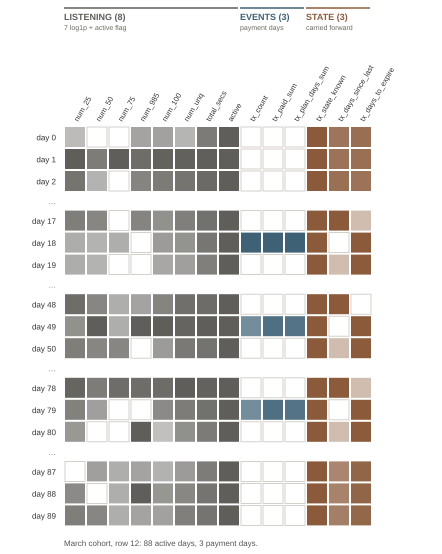

In [ ]:
from IPython.display import SVG, display

X_fig = lstm['test']
active_i, pay_i = EXPORT_CHANNELS.index('active'), EXPORT_CHANNELS.index('tx_count')
for fig_row in range(len(X_fig)):
    slice_ = np.asarray(X_fig[fig_row], dtype=np.float32)
    if slice_[:, active_i].sum() >= 60 and (slice_[:, pay_i] > 0).sum() >= 3:
        break
pay_days = np.flatnonzero(slice_[:, pay_i] > 0)
fig_days = sorted({0, 1, 2, SEQ_DAYS - 3, SEQ_DAYS - 2, SEQ_DAYS - 1}
                  | {int(d) for p in pay_days for d in (p - 1, p, p + 1) if 0 <= d < SEQ_DAYS})
display(SVG(tensor_slice_svg(
    slice_, sequence_channel_specs(EXPORT_CHANNELS), fig_days,
    caption=f'March cohort, row {fig_row}: {int(slice_[:, active_i].sum())} active days, '
            f'{len(pay_days)} payment days.')))

## 9. Export

`export_sequence_dataset` validates that the tensor, labels and cohort users
share the same row count and the same `msno` order. It computes a SHA-1 digest
of that order and requires it to match before writing
`labels_<cohort>.parquet`. `metadata.json` is deleted at the start of the export
and written last, atomically; its presence therefore means that the export is
complete. `verify_export` re-reads the array, labels and metadata from disk and
checks the digest again.


In [ ]:
run_config = {
    'cutoffs': CUTOFF, 'label_months': LABEL_MONTHS, 'label_files': LABEL_FILES,
    'splits': SPLITS, 'seq_days': SEQ_DAYS,
    'log_sources': ['user_logs.parquet', 'user_logs_v2.parquet'],
    'windows': {split: {'start': str(sequence_start(c).date()), 'cutoff': c} for split, c in CUTOFF.items()},
    'listening_encoding': 'log1p, unscaled (scalers are fit in the model notebook)',
    'sample_users': SAMPLE_USERS,
    'segment': {'name': 'manual', 'rule': 'last transaction day up to the cutoff: payment, no auto-renew, no cancel',
                'reports': segment_reports},
}
metadata = export_sequence_dataset(EXPORT_DIR, lstm, labels, users_by_split, sequence_audit,
                                   run_config, dataset_version=DATASET_VERSION,
                                   channels=EXPORT_CHANNELS)
verify_export(EXPORT_DIR, users_by_split)
print('Export verified:', EXPORT_DIR.resolve())
print('Peak RAM:', round(resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1e6, 2), 'GB')
export_summary(EXPORT_DIR)

Export verified: /home/alejandropenagos/Escritorio/Alejandro/Machine Learning/customer-churn-prediction/workshops/w2/export-sequential-v6-manual
Peak RAM: 5.04 GB


,file,MB
0,labels_test.parquet,4.08
1,labels_train_feb.parquet,4.00
2,metadata.json,0.01
3,seq_lstm_test.npy,286.95
4,seq_lstm_train_feb.npy,281.61
5,sequence_audit.json,0.01


## 10. Consuming v6

| File | Content |
|---|---|
| `seq_lstm_<cohort>.npy` | `(users, 90, 14)` `float16`, days oldest to newest |
| `labels_<cohort>.parquet` | `row`, `msno`, `is_churn` in the same row order |
| `metadata.json` | cutoffs, segment, the 14 channels, shapes, row hashes and audit |
| `sequence_audit.json` | audit summary per cohort |

| Group | Channels | Slice |
|---|---|---|
| listening (8) | `num_25` … `total_secs`, `active` | `0:8` |
| payment events (3) | `tx_count`, `tx_paid_sum`, `tx_plan_days_sum` | `8:11` |
| payment state (3) | `tx_state_known`, `tx_days_since_last`, `tx_days_to_expire` | `11:14` |

The model notebooks read this export through `src/models/constants.py`
(`EXPORT_NAME`) and feed the 14 channels to the networks. A reader should load
the array with `mmap_mode="r"` when full materialisation is not needed, verify
`dataset_version == 6`, the channel names, the shape and `dtype`, and compare
the label/array row hash exposed in `metadata.json`.

In [ ]:
# How a model notebook reads the export.
X = np.load(EXPORT_DIR / 'seq_lstm_test.npy', mmap_mode='r')     # no full load into RAM
y = pl.read_parquet(EXPORT_DIR / 'labels_test.parquet')['is_churn'].to_numpy()
channels = json.loads((EXPORT_DIR / 'metadata.json').read_text())['sequences']['lstm']['channels']
assert channels == EXPORT_CHANNELS
print('X:', X.shape, X.dtype, '| y:', y.shape, '| churn rate:', round(float(y.mean()), 4))
print('listening:', X[:, :, :8].shape, '| payment events:', X[:, :, 8:11].shape, '| payment state:', X[:, :, 11:].shape)

X: (113870, 90, 14) float16 | y: (113870,) | churn rate: 0.411
listening: (113870, 90, 8) | payment events: (113870, 90, 3) | payment state: (113870, 90, 3)
